In [1]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selection_result(results, ax, budget=None, label=None, color=None):
    import scipy.stats as sps

    if budget is None:
        budget = results.shape[-1]

    def ci(y):
        br = sps.bootstrap((y,), np.mean, vectorized=True)
        ci_l = br.confidence_interval.low
        ci_u = br.confidence_interval.high
        return ci_l, ci_u

    iters = np.arange(0, budget, 1)
    agg_value = results.mean(axis=0)[:budget].ravel()
    _ci_lb, _ci_ub = ci(results)[:budget]

    line, *_ = ax.plot(iters, agg_value, linewidth=1.5, label=label, color=color)

    ax.plot(iters, _ci_lb, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.plot(iters, _ci_ub, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.fill_between(iters, _ci_lb, _ci_ub, alpha=0.3, color=line.get_color())


In [2]:
import torch
import pandas as pd



# results  dimscaled prior
_path = "data/edbo_suzuki_features_matern52_dimscaled.txt"

tidyhebo_m52_dimscaled_out = np.loadtxt(_path)
tidyhebo_r1 = torch.from_numpy(tidyhebo_m52_dimscaled_out).cummax(axis=1).values.detach().numpy()

# results
_path = "data/edbo_suzuki_edbo.txt"
edbo_out = np.loadtxt(_path)
edbo_res = torch.from_numpy(edbo_out).cummax(axis=1).values.detach().numpy()
edbo_res = edbo_res[:, :100]

# qlogei defauls
_path = "data/edbo_features_default_qlogei.txt"
qlogei_default = np.loadtxt(_path)
qlogei = torch.from_numpy(qlogei_default).cummax(axis=1).values.detach().numpy()

# random
df = pd.read_csv("data/suzuki_embedded.csv", index_col=0)
random_out = [df.sample(100)["yield"].to_numpy() for _ in range(50)]
random_out = np.vstack(random_out)
random_res = torch.from_numpy(random_out).cummax(axis=1).values.detach().numpy()


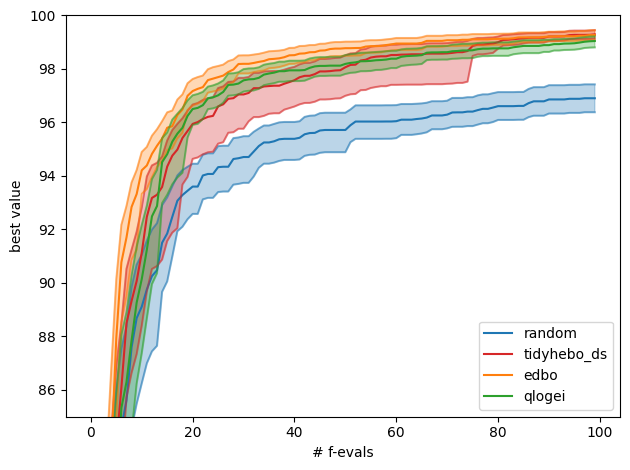

In [3]:
import matplotlib.pyplot as plt


fig = plt.gcf()
ax = plt.gca()

plot_selection_result(random_res, ax, budget=100, label="random", color="tab:blue")
plot_selection_result(tidyhebo_r1, ax, budget=100, label="tidyhebo_ds", color="tab:red")
plot_selection_result(edbo_res, ax, budget=100, label="edbo", color="tab:orange")
plot_selection_result(qlogei, ax, budget=100, label="qlogei", color="tab:green")

ax.legend()
# fig.suptitle("Сходимость моделей (suzuki)")
ax.set_ylabel("best value")
ax.set_xlabel("# f-evals")
ax.set_ylim(bottom=85, top=100)

fig.tight_layout()